# In-class problem

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix,roc_auc_score,roc_curve


# Load the SuperCon dataset
df = pd.read_csv("data/Supercon.csv")
print(df.head())
print(f"Number of samples: {len(df)}")

                 composition     Tc
0            Ba0.4K0.6Fe2As2  31.20
1  Ca0.4Ba1.25La1.25Cu3O6.98  40.10
2               Mo0.39Ru0.61   6.90
3                 Tm4Os6Sn19   1.10
4  Nd1Bi0.99Pb0.01S2F0.3O0.7   4.85
Number of samples: 16406


In [4]:
df.shape

(16406, 2)

In [5]:
threshold = 30  # Example threshold in Kelvin
df['is_superconductor'] = (df['Tc'] >= threshold).astype(int)

print(df[['composition', 'Tc', 'is_superconductor']].head())


                 composition     Tc  is_superconductor
0            Ba0.4K0.6Fe2As2  31.20                  1
1  Ca0.4Ba1.25La1.25Cu3O6.98  40.10                  1
2               Mo0.39Ru0.61   6.90                  0
3                 Tm4Os6Sn19   1.10                  0
4  Nd1Bi0.99Pb0.01S2F0.3O0.7   4.85                  0


In [6]:
from matminer.featurizers.composition import ElementProperty
from pymatgen.core.composition import Composition

In [7]:

# Convert formula strings to Composition objects
df['composition'] = df['composition'].apply(Composition)


# Define a featurizer
ep_feat = ElementProperty.from_preset(preset_name="magpie")

# Generate features
feature_df = ep_feat.featurize_dataframe(df, col_id='composition')

print(feature_df.head())

C:\Users\Sasani\AppData\Local\anaconda3\envs\mle5217\lib\site-packages\matminer\utils\data.py:326: UserWarning: MagpieData(impute_nan=False):
In a future release, impute_nan will be set to True by default.
                    This means that features that are missing or are NaNs for elements
                    from the data source will be replaced by the average of that value
                    over the available elements.
                    This avoids NaNs after featurization that are often replaced by
                    dataset-dependent averages.
  warnings.warn(f"{self.__class__.__name__}(impute_nan=False):\n" + IMPUTE_NAN_WARNING)


ElementProperty:   0%|          | 0/16406 [00:00<?, ?it/s]

             composition     Tc  is_superconductor  MagpieData minimum Number  \
0        (Ba, K, Fe, As)  31.20                  1                       19.0   
1    (Ca, Ba, La, Cu, O)  40.10                  1                        8.0   
2               (Mo, Ru)   6.90                  0                       42.0   
3           (Tm, Os, Sn)   1.10                  0                       50.0   
4  (Nd, Bi, Pb, S, F, O)   4.85                  0                        8.0   

   MagpieData maximum Number  MagpieData range Number  MagpieData mean Number  \
0                       56.0                     37.0               30.360000   
1                       57.0                     49.0               22.677795   
2                       44.0                      2.0               43.220000   
3                       76.0                     26.0               58.000000   
4                       83.0                     75.0               36.658000   

   MagpieData avg_dev Numb

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.preprocessing import StandardScaler


In [10]:
X = feature_df.drop(columns=['Tc', 'is_superconductor', 'composition'])
y = feature_df['is_superconductor']

In [11]:
from collections import Counter
print(Counter(y))

Counter({0: 12968, 1: 3438})


In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify=y)

In [13]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [14]:
# Initialize the Random Forest Classifier
rf_classifier = RandomForestClassifier(
    class_weight='balanced',
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
#n_estimators : number of trees in the forest
#criterion : 'gini' by default
#n_jobs:specifies the number of CPU cores used during the training and prediction phases of the model. by default 1, -1 means all CPUs in parallel


In [15]:
rf_classifier.fit(X_train_scaled, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [16]:
y_pred = rf_classifier.predict(X_test_scaled)
accuracy = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {accuracy:.2f}")

Test Accuracy: 0.94



Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.96      0.96      2594
           1       0.85      0.85      0.85       688

    accuracy                           0.94      3282
   macro avg       0.91      0.90      0.91      3282
weighted avg       0.94      0.94      0.94      3282



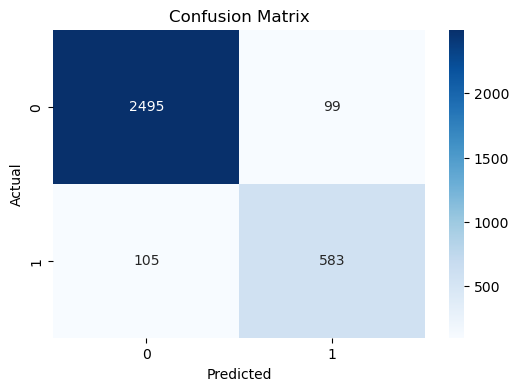

In [17]:
# Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix


cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

C:\Users\Sasani\AppData\Local\anaconda3\envs\mle5217\lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


ROC AUC Score: 0.81


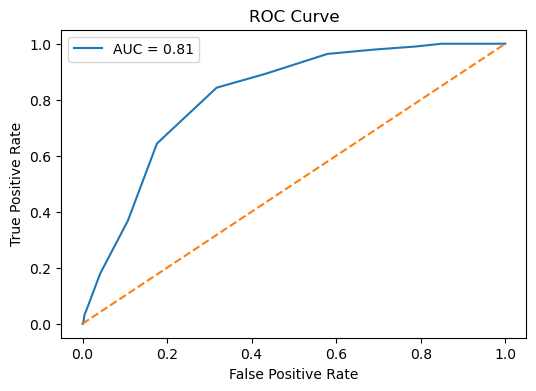

In [18]:
# Compute ROC AUC
y_prob = rf_classifier.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_prob)
print(f"ROC AUC Score: {roc_auc:.2f}")

# Plot ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.2f}')
plt.plot([0, 1], [0, 1], linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()


In [19]:
# Dimensionality Reduction: 1st step Feature Importance
# Get feature importances
importances = rf_classifier.feature_importances_
indices = np.argsort(importances)[::-1]   #[::-1] - start and stop is not defined, so this will sort all importances in ascending order, -1 will reverse that
#So, the indices will be in descending order - with high importance first
feature_names = X.columns

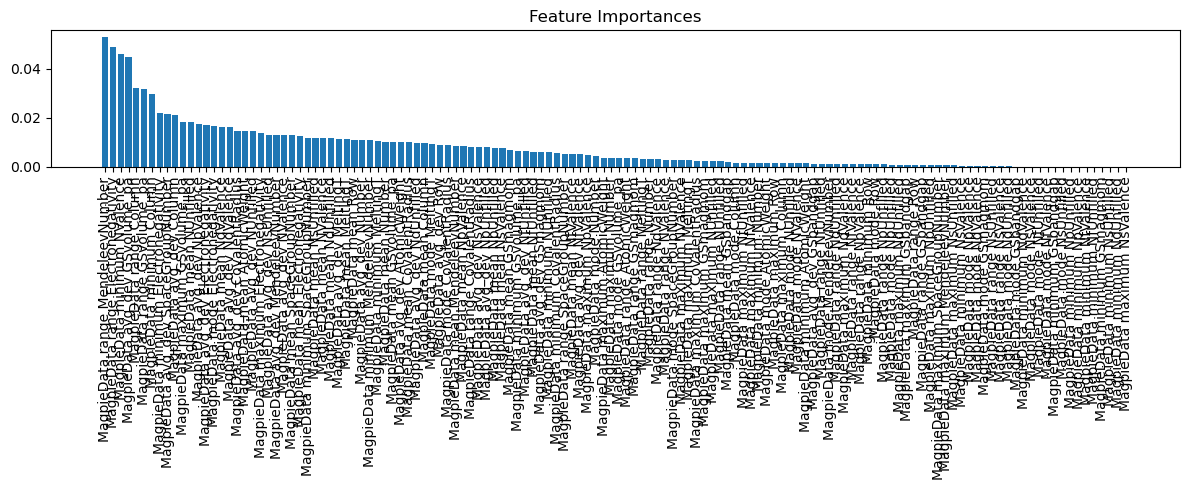

In [20]:
# Plot the feature importances
plt.figure(figsize=(12,5))
plt.title("Feature Importances")
plt.bar(range(X.shape[1]), importances[indices], align="center")
plt.xticks(range(X.shape[1]), feature_names[indices], rotation=90)
plt.tight_layout()
plt.show()

In [21]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    #'n_estimators': [100, 300, 500],
    'max_depth': [10, 20, 30],
    'min_samples_split': [10,20,50],
    'min_samples_leaf': [10, 20, 40],
    'max_features': ['sqrt']#, 'log2', None]
}

grid_search = GridSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid,
    cv=5,
    scoring='roc_auc',
    verbose=2
)

grid_search.fit(X_train_scaled, y_train)
print(f"Best parameters: {grid_search.best_params_}")
print(f"Best ROC AUC: {grid_search.best_score_:.4f}")


Fitting 5 folds for each of 27 candidates, totalling 135 fits
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=10; total time=   1.3s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=10; total time=   1.3s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=10; total time=   1.6s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=10; total time=   1.4s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=10; total time=   1.4s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=20; total time=   1.4s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=20; total time=   1.5s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=20; total time=   1.3s
[CV] END max_depth=10, max_features=sqrt, min_samples_leaf=10, min_samples_split=20; total time=   1.3s
[C

In [22]:
rf_classifier_bestparam = RandomForestClassifier(
    class_weight='balanced',
    n_estimators=100,
    max_depth=30,
    max_features='sqrt',
    min_samples_leaf=10,
    min_samples_split=10,
    random_state=42,
    n_jobs=-1,
)


In [23]:
rf_classifier_bestparam.fit(X_train_scaled, y_train)

# Make predictions
y_pred_bestparam = rf_classifier_bestparam.predict(X_test)
accuracy_bestparam = accuracy_score(y_test, y_pred_bestparam)
print(f"Accuracy (with best parameters): {accuracy_bestparam:.2f}")

C:\Users\Sasani\AppData\Local\anaconda3\envs\mle5217\lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


Accuracy (with best parameters): 0.79


In [24]:
# Classification Report
print("\nClassification Report (best parameters):")
print(classification_report(y_test, y_pred_bestparam))



Classification Report (best parameters):
              precision    recall  f1-score   support

           0       0.79      1.00      0.88      2594
           1       0.00      0.00      0.00       688

    accuracy                           0.79      3282
   macro avg       0.40      0.50      0.44      3282
weighted avg       0.62      0.79      0.70      3282



C:\Users\Sasani\AppData\Local\anaconda3\envs\mle5217\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Sasani\AppData\Local\anaconda3\envs\mle5217\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\Sasani\AppData\Local\anaconda3\envs\mle5217\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, 

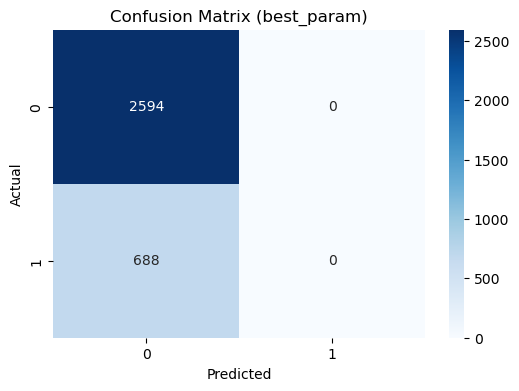

In [25]:
# Confusion Matrix
best_param = confusion_matrix(y_test, y_pred_bestparam)
plt.figure(figsize=(6, 4))
sns.heatmap(best_param, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix (best_param)')
plt.show()


In [26]:
#Parameter optimization (like GridSearchCV or RandomizedSearchCV) can sometimes:
#*Overfit on the cross-validation splits, particularly if the data is imbalanced.
#*Focus on overall accuracy or metrics dominated by the majority class, leading to a biased model that favors the majority class.
#*Get stuck in local minima in hyperparameter space, selecting parameters that don’t generalize well.

#Our initial un-optimized result is generally good.
#for optimization perhaps we need to look at a broader scope of parameters - need more compute!
#So let's leave this as is with the un-optimized model as the better one!
